# DataWizards · Guía 4 | Perfilamiento y EDA crítico del RUNT 2.0

**Conjunto:** Vehículos eléctricos e híbridos matriculados en Colombia · descarga 2026-11-14  
**Dimensión del proyecto:** demanda potencial para priorizar ciudades colombianas para estudios de prefactibilidad de carga pública rápida  
**Estado:** EDA exploratorio, **no** ranking de inversión ni estimación de uso de cargadores.

**Preguntas:** (1) ¿Qué mide realmente la fuente? (2) ¿Qué tan completa, coherente y comparable es? (3) ¿Cómo cambia la distribución geográfica al separar eléctricos e híbridos y clases vehiculares? (4) ¿Cuánto de la conclusión depende de decisiones de limpieza/filtro?  

**Advertencias:** una fila es una *celda agregada*, no un vehículo. Todos los totales y distribuciones de vehículos deben usar la ponderación `CANTIDAD`. El municipio de matrícula no identifica necesariamente residencia, circulación ni consumo de carga. El archivo no identifica directamente híbridos enchufables. El año 2026 no es comparable con un año completo. No hay variable objetivo observada para predicción de rentabilidad. No se infieren mecanismos MCAR/MAR/MNAR ni causalidad.

**Fuente declarada:** Portal Nacional de Datos Abiertos, conjunto `ntxy-q9ix`: https://www.datos.gov.co/d/ntxy-q9ix. La periodicidad real de actualización, metodología de captura, exhaustividad y licencia deben confirmarse en la ficha de metadatos. No se infieren del archivo.

In [1]:
# ÚNICO BLOQUE DE IMPORTACIONES Y CONFIGURACIÓN
from pathlib import Path
from datetime import datetime
import hashlib
import json
import sys
import warnings
import numpy as np
import pandas as pd
import scipy
from scipy.stats import spearmanr, kendalltau, entropy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.figsize': (11, 5.5), 'axes.spines.top': False, 'axes.spines.right': False, 'savefig.dpi': 150, 'font.size': 10})
SEED = 42
rng = np.random.default_rng(SEED)
# Reproducible tanto desde el repositorio local como desde el paquete de entrega.
candidates = [
    Path('../data/raw/runt_andi/VEHÍCULOS_ELÉCTRICOS_E_HÍBRIDOS_MATRICULADOS_EN_COLOMBIA_-_RUNT_2.0_20261114.csv'),
    Path('data/raw/runt_andi/VEHÍCULOS_ELÉCTRICOS_E_HÍBRIDOS_MATRICULADOS_EN_COLOMBIA_-_RUNT_2.0_20261114.csv'),
    Path('../VEHÍCULOS_ELÉCTRICOS_E_HÍBRIDOS_MATRICULADOS_EN_COLOMBIA_-_RUNT_2.0_20261114.csv'),
    Path('VEHÍCULOS_ELÉCTRICOS_E_HÍBRIDOS_MATRICULADOS_EN_COLOMBIA_-_RUNT_2.0_20261114.csv'),
    Path('/mnt/data/VEHÍCULOS_ELÉCTRICOS_E_HÍBRIDOS_MATRICULADOS_EN_COLOMBIA_-_RUNT_2.0_20261114.csv'),
]
path = next((p.resolve() for p in candidates if p.exists()), None)
if path is None: raise FileNotFoundError('Ubique el CSV original en data/raw/runt_andi, sin alterar su nombre')
OUT = Path('../reports') if Path('../reports').exists() else Path('reports')
(OUT/'figures').mkdir(parents=True,exist_ok=True)
(OUT/'tables').mkdir(parents=True,exist_ok=True)
print('Entrada:',path.name,'| bytes:',path.stat().st_size)
print('SHA256:',hashlib.sha256(path.read_bytes()).hexdigest())
print('Versiones:',{'python':sys.version.split()[0], 'pandas':pd.__version__, 'numpy':np.__version__, 'scipy':scipy.__version__, 'matplotlib':matplotlib.__version__})

Entrada: VEHÍCULOS_ELÉCTRICOS_E_HÍBRIDOS_MATRICULADOS_EN_COLOMBIA_-_RUNT_2.0_20261114.csv | bytes: 842330
SHA256: 6c097fa08621d6ae36cd7567f4efb8ffed78d5efc76f77a5a3d6971017b96154
Versiones: {'python': '3.13.5', 'pandas': '2.2.3', 'numpy': '2.3.5', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}


## 1 · Auditoría de estructura y unidad de observación
**Pregunta:** ¿Qué representa cada registro?  
**Método:** inspección del CSV preservando las ocho columnas como texto antes de convertir valores.  
**Decisión metodológica:** no sumar filas como si fuesen vehículos; interpretar `CANTIDAD` con separadores de miles. Se reportan tanto recuentos de filas como sumas ponderadas de vehículos.

In [2]:
raw = pd.read_csv(path, encoding='utf-8-sig', dtype='string', keep_default_na=True)
print('Dimensiones:',raw.shape)
display(raw.head(8))
print('Columnas:',raw.columns.tolist())
print('Nulos por variable:')
display(pd.DataFrame({'tipo_archivo':raw.dtypes.astype(str), 'faltantes':raw.isna().sum(), 'porcentaje_faltantes':raw.isna().mean().mul(100).round(3), 'cardinalidad':raw.nunique(dropna=True)}))
assert raw.shape[1] == 8, 'Se modificó el esquema esperado; revisar columnas'

Dimensiones: (10748, 8)


,COMBUSTIBLE,MODELO,AÑO_REGISTRO,CLASE,CARROCERIA,MUNICIPIO,DEPARTAMENTO,CANTIDAD
0,ELECTRICO,2016,2015,AUTOMOVIL,COUPE,ENVIGADO,Antioquia,14
1,ELECTRICO,2012,2015,AUTOMOVIL,BUGGY,ENVIGADO,Antioquia,2
2,ELECTRICO,2015,2015,AUTOMOVIL,COUPE,ENVIGADO,Antioquia,2
3,ELECTRICO,2016,2015,AUTOMOVIL,COUPE,MEDELLIN,Antioquia,18
4,ELECTRICO,2016,2015,AUTOMOVIL,COUPE,LA CEJA,Antioquia,1
5,ELECTRICO,2012,2015,AUTOMOVIL,BUGGY,SAN JERONIMO,Antioquia,1
6,ELECTRICO,2015,2015,AUTOMOVIL,HATCH BACK,ENVIGADO,Antioquia,1
7,ELECTRICO,2016,2015,AUTOMOVIL,COUPE,SABANETA,Antioquia,2


Columnas: ['COMBUSTIBLE', 'MODELO', 'AÑO_REGISTRO', 'CLASE', 'CARROCERIA', 'MUNICIPIO', 'DEPARTAMENTO', 'CANTIDAD']
Nulos por variable:


,tipo_archivo,faltantes,porcentaje_faltantes,cardinalidad
COMBUSTIBLE,string,0,0.000,4
MODELO,string,0,0.000,26
AÑO_REGISTRO,string,0,0.000,12
CLASE,string,0,0.000,16
CARROCERIA,string,1,0.009,51
MUNICIPIO,string,0,0.000,262
DEPARTAMENTO,string,0,0.000,32
CANTIDAD,string,0,0.000,392


## 2 · Tipado controlado, rangos y coherencia
Se distingue `MODELO` (año modelo del vehículo) de `AÑO_REGISTRO` (año de matrícula); no son equivalentes. Un modelo posterior al año de registro merece revisión semántica, **no** eliminación automática. Los datos originales permanecen intactos.

In [3]:
df=raw.copy()
for c in ['COMBUSTIBLE','CLASE','CARROCERIA','MUNICIPIO','DEPARTAMENTO']:
    df[c]=df[c].str.strip()
df['CANTIDAD_NUM']=pd.to_numeric(df['CANTIDAD'].str.replace(',','',regex=False).str.replace(' ','',regex=False),errors='coerce')
df['REGISTRO_ANO']=pd.to_numeric(df['AÑO_REGISTRO'],errors='coerce')
df['MODELO_ANO']=pd.to_numeric(df['MODELO'],errors='coerce')
df['MUNICIPIO_DPTO']=df['MUNICIPIO'].fillna('SIN MUNICIPIO')+' | '+df['DEPARTAMENTO'].fillna('SIN DEPARTAMENTO')
key=['COMBUSTIBLE','MODELO','AÑO_REGISTRO','CLASE','CARROCERIA','MUNICIPIO','DEPARTAMENTO']
checks={
 'filas':len(df),'cantidad_vehiculos':int(df['CANTIDAD_NUM'].sum()),
 'filas_cantidad_con_coma':int(df['CANTIDAD'].str.contains(',',regex=False,na=False).sum()),
 'cantidad_invalida':int(df['CANTIDAD_NUM'].isna().sum()),
 'cantidad_no_positiva':int((df['CANTIDAD_NUM']<=0).sum()),
 'filas_exactamente_duplicadas':int(raw.duplicated().sum()),
 'claves_agregadas_duplicadas':int(df.duplicated(key).sum()),
 'faltantes_totales':int(raw.isna().sum().sum()),
 'municipios_distintos_nombre':int(df['MUNICIPIO'].nunique()),
 'municipios_distintos_par_municipio_departamento':int(df['MUNICIPIO_DPTO'].nunique()),
 'departamentos':int(df['DEPARTAMENTO'].nunique()),
 'min_ano_registro':int(df['REGISTRO_ANO'].min()),
 'max_ano_registro':int(df['REGISTRO_ANO'].max()),
 'min_ano_modelo':int(df['MODELO_ANO'].min()),
 'max_ano_modelo':int(df['MODELO_ANO'].max()),
 'modelo_posterior_registro_filas':int((df['MODELO_ANO']>df['REGISTRO_ANO']).sum()),
 'modelo_posterior_registro_vehiculos':int(df.loc[df['MODELO_ANO']>df['REGISTRO_ANO'],'CANTIDAD_NUM'].sum()),
 'modelo_posterior_en_mas_de_un_ano_filas':int((df['MODELO_ANO']>df['REGISTRO_ANO']+1).sum()),
 'anio_2026_vehiculos':int(df.loc[df['REGISTRO_ANO']==2026,'CANTIDAD_NUM'].sum()),
}
display(pd.Series(checks,name='valor').to_frame())
assert checks['cantidad_invalida']==0 and checks['cantidad_no_positiva']==0
(OUT/'tables'/'indicadores_auditoria_runt.json').write_text(json.dumps(checks,ensure_ascii=False,indent=2),encoding='utf-8')

,valor
filas,10748
cantidad_vehiculos,332901
filas_cantidad_con_coma,53
cantidad_invalida,0
cantidad_no_positiva,0
filas_exactamente_duplicadas,0
claves_agregadas_duplicadas,0
faltantes_totales,1
municipios_distintos_nombre,262
municipios_distintos_par_municipio_departamento,265


639

## 3 · Matriz de calidad y decisiones de limpieza
Clasificación **provisional**: una sospecha de negocio no equivale a un error confirmado. La imputación de categorías ausentes no se hace sin evidencia externa. El año 2026 se conserva marcado como parcial.

In [4]:
quality=pd.DataFrame([
 ['Q01','CANTIDAD como texto y separador de miles',f"{checks['filas_cantidad_con_coma']} filas incluyen coma",'Alto','Alto','Convertir a número quitando coma; validar valores positivos','Aplicado en columna derivada CANTIDAD_NUM'],
 ['Q02','Faltante en CARROCERIA',f"{int(df['CARROCERIA'].isna().sum())} fila(s)",'Bajo','Bajo','Conservar NA como categoría no informada; no inventar carrocería','Pendiente de codificación de categoría para modelado'],
 ['Q03','MODELO posterior a año registro',f"{checks['modelo_posterior_registro_filas']} filas; {checks['modelo_posterior_registro_vehiculos']} vehículos",'Medio','Medio','Evaluar diferencias por año y categoría; no eliminar automáticamente','En revisión; posibles años modelo futuros'],
 ['Q04','2026 en curso',f"{checks['anio_2026_vehiculos']} vehículos con año registro 2026",'Alto','Alto','Marcar como periodo incompleto; no comparar contra años enteros','Aplicado como restricción interpretativa'],
 ['Q05','Combinación de eléctricos y distintas clases híbridas', 'Categorías: '+', '.join(df['COMBUSTIBLE'].dropna().unique().tolist()),'Alto','Alto','Separar ELECTRICO; no suponer que híbridos son enchufables','Filtrado analítico, fuente intacta'],
 ['Q06','Municipio de matrícula ≠ demanda geográfica de carga',f"{checks['municipios_distintos_par_municipio_departamento']} pares municipio-departamento",'Alto','Alto','Validar contra movilidad y otras fuentes; tratar proxy como indicador parcial','Riesgo pendiente de triangulación'],
 ['Q07','Falta precisión temporal mensual','Sólo AÑO_REGISTRO','Alto','Alto','No calcular crecimiento móvil de 12 meses con este archivo','Limitación no subsanable sin fuente adicional'],
 ['Q08','Año de matrícula y posible estado del vehículo','Archivo no contiene baja/activo ni fecha exacta','Alto','Medio','No llamar parque activo a acumulados sin confirmación documental','Pendiente verificación metadatos y metodología'],
 ['Q09','Homologación territorial DIVIPOLA','No aparece código oficial municipal','Alto','Medio','Cruce y control de ambigüedades con catálogo DIVIPOLA','Pendiente de fuente externa'],
],columns=['id','problema','evidencia','impacto','gravedad','tratamiento_recomendado','estado'])
display(quality)
quality.to_csv(OUT/'tables'/'matriz_calidad_runt.csv',index=False,encoding='utf-8-sig')

,id,problema,evidencia,impacto,gravedad,tratamiento_recomendado,estado
0,Q01,CANTIDAD como texto y separador de miles,53 filas incluyen coma,Alto,Alto,Convertir a número quitando coma; validar valores positivos,Aplicado en columna derivada CANTIDAD_NUM
1,Q02,Faltante en CARROCERIA,1 fila(s),Bajo,Bajo,Conservar NA como categoría no informada; no inventar carrocería,Pendiente de codificación de categoría para modelado
2,Q03,MODELO posterior a año registro,3694 filas; 174737 vehículos,Medio,Medio,Evaluar diferencias por año y categoría; no eliminar automáticamente,En revisión; posibles años modelo futuros
3,Q04,2026 en curso,87961 vehículos con año registro 2026,Alto,Alto,Marcar como periodo incompleto; no comparar contra años enteros,Aplicado como restricción interpretativa
4,Q05,Combinación de eléctricos y distintas clases híbridas,"Categorías: ELECTRICO, GASO ELEC, DIES ELEC, HIDROGENO",Alto,Alto,Separar ELECTRICO; no suponer que híbridos son enchufables,"Filtrado analítico, fuente intacta"
5,Q06,Municipio de matrícula ≠ demanda geográfica de carga,265 pares municipio-departamento,Alto,Alto,Validar contra movilidad y otras fuentes; tratar proxy como indicador parcial,Riesgo pendiente de triangulación
6,Q07,Falta precisión temporal mensual,Sólo AÑO_REGISTRO,Alto,Alto,No calcular crecimiento móvil de 12 meses con este archivo,Limitación no subsanable sin fuente adicional
7,Q08,Año de matrícula y posible estado del vehículo,Archivo no contiene baja/activo ni fecha exacta,Alto,Medio,No llamar parque activo a acumulados sin confirmación documental,Pendiente verificación metadatos y metodología
8,Q09,Homologación territorial DIVIPOLA,No aparece código oficial municipal,Alto,Medio,Cruce y control de ambigüedades con catálogo DIVIPOLA,Pendiente de fuente externa


## 4 · Distribuciones ponderadas y composición de tecnologías
**Pregunta:** ¿Cuál es la composición registrada y por qué importa?  
**Método:** agregación por categoría usando `sum(CANTIDAD_NUM)`. Las categorías originales se mantienen sin asumir correspondencias con PHEV/HEV.

Unidades por combustible


,vehiculos,porcentaje
COMBUSTIBLE,,
GASO ELEC,239851,72.05
ELECTRICO,89900,27.01
DIES ELEC,3146,0.95
HIDROGENO,4,0.0


Clases (top 16)


,vehiculos
CLASE,
CAMIONETA,229794
AUTOMOVIL,65686
CICLOMOTOR,15622
CAMPERO,14247
BUS,1906
CUADRICICLO,1602
MOTOCICLETA,1552
MOTOCARRO,992
CAMION,804


Años de registro


,vehiculos
REGISTRO_ANO,
2015,586
2016,504
2017,450
2018,2104
2019,5435
2020,7908
2021,20304
2022,30513
2023,34039


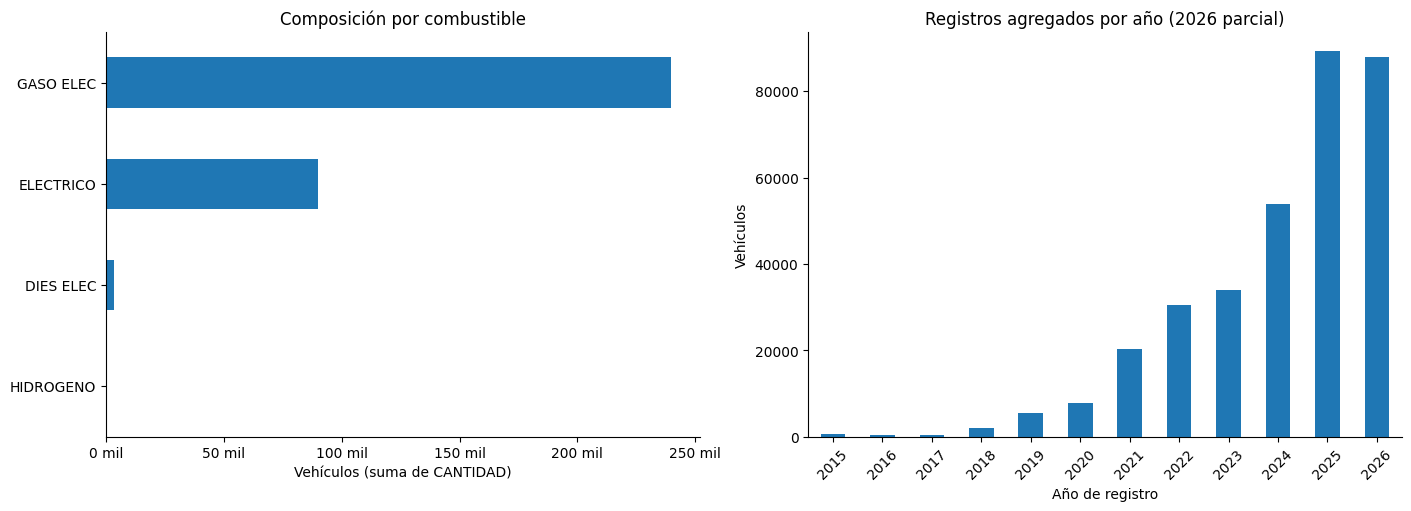

NOTA: 2026 es año incompleto. No se concluye crecimiento a partir de su comparación con 2025.


In [5]:
fuel=df.groupby('COMBUSTIBLE',dropna=False,observed=True)['CANTIDAD_NUM'].sum().sort_values(ascending=False)
classes=df.groupby('CLASE',observed=True)['CANTIDAD_NUM'].sum().sort_values(ascending=False)
years=df.groupby('REGISTRO_ANO',observed=True)['CANTIDAD_NUM'].sum().sort_index()
print('Unidades por combustible');display(fuel.to_frame('vehiculos').assign(porcentaje=(fuel/fuel.sum()*100).round(2)))
print('Clases (top 16)');display(classes.to_frame('vehiculos'))
print('Años de registro');display(years.to_frame('vehiculos'))
fig,axs=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
fuel.sort_values().plot.barh(ax=axs[0]);axs[0].set(title='Composición por combustible',xlabel='Vehículos (suma de CANTIDAD)',ylabel='')
axs[0].xaxis.set_major_formatter(FuncFormatter(lambda x,_:f'{x/1000:,.0f} mil'))
years.plot.bar(ax=axs[1]);axs[1].set(title='Registros agregados por año (2026 parcial)',xlabel='Año de registro',ylabel='Vehículos');axs[1].tick_params(axis='x',rotation=45)
fig.savefig(OUT/'figures'/'01_composicion_y_anios.png',bbox_inches='tight');plt.show()
print('NOTA: 2026 es año incompleto. No se concluye crecimiento a partir de su comparación con 2025.')

## 5 · Perfil numérico de la celda agregada, concentración y outliers
El valor `CANTIDAD_NUM` representa **tamaño de una celda de agregación**, no la variable de un vehículo individual ni una muestra de observaciones independientes. Se usan estadísticos descriptivos (incluidos IQR, MAD, asimetría) sobre tamaños de celdas; **no** se interpretan outliers como registros erróneos. Una prueba formal de normalidad de estas celdas no sería requisito para la priorización multicriterio y puede confundir tamaños de grupos con demanda individual: se descarta motivadamente.

,valor
media,30.973
mediana,2.000
minimo,1.000
maximo,17230.000
varianza,83908.331
desviacion_estandar,289.669
Q1,1.000
Q3,7.000
IQR,6.000
MAD,1.000


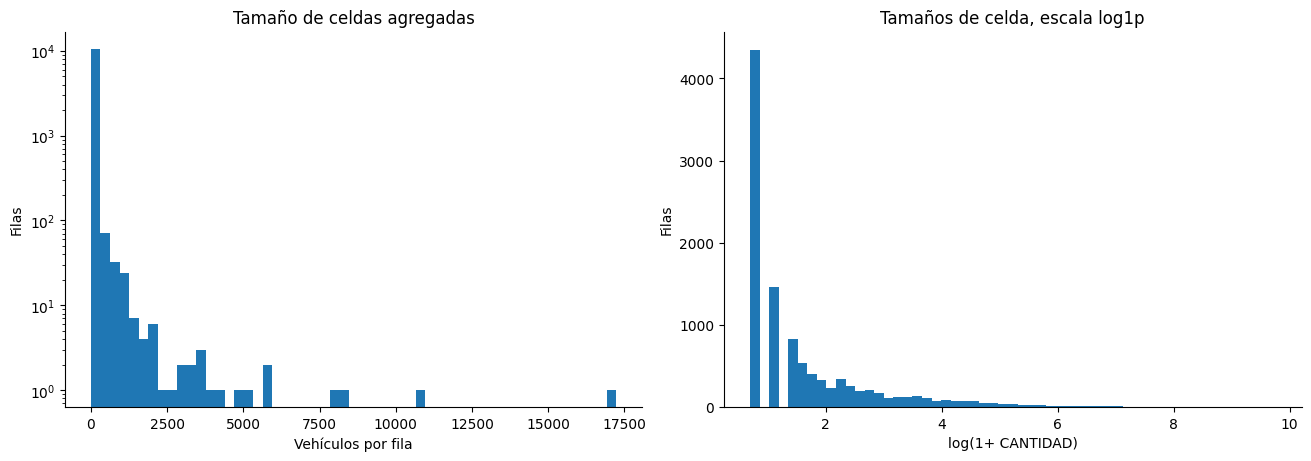

Decisión: no eliminar outliers por IQR; grandes cantidades pueden describir celdas legítimas.


In [6]:
x=df['CANTIDAD_NUM'].to_numpy(dtype=float)
q1,q3=np.quantile(x,[.25,.75]);iqr=q3-q1;med=np.median(x);mad=np.median(abs(x-med));fence=q3+1.5*iqr
stats=pd.Series({'media':np.mean(x),'mediana':med,'minimo':np.min(x),'maximo':np.max(x),'varianza':np.var(x,ddof=1),'desviacion_estandar':np.std(x,ddof=1),'Q1':q1,'Q3':q3,'IQR':iqr,'MAD':mad,'p90':np.quantile(x,.9),'p95':np.quantile(x,.95),'p99':np.quantile(x,.99),'asimetria':pd.Series(x).skew(),'curtosis_exceso':pd.Series(x).kurt(),'filas_por_encima_Tukey':int((x>fence).sum()),'vehiculos_en_filas_Tukey':int(x[x>fence].sum())})
display(stats.to_frame('valor').round(3))
fig,axs=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
axs[0].hist(x,bins=55);axs[0].set(title='Tamaño de celdas agregadas',xlabel='Vehículos por fila',ylabel='Filas');axs[0].set_yscale('log')
axs[1].hist(np.log1p(x),bins=55);axs[1].set(title='Tamaños de celda, escala log1p',xlabel='log(1+ CANTIDAD)',ylabel='Filas')
fig.savefig(OUT/'figures'/'02_tamanos_celda.png',bbox_inches='tight');plt.show()
print('Decisión: no eliminar outliers por IQR; grandes cantidades pueden describir celdas legítimas.')

## 6 · Composición eléctrica y clases por municipio
**Pregunta:** ¿Qué ciudades concentran los vehículos `ELECTRICO` y qué clases aportan?  
**Método:** agrupación municipal usando clave compuesta municipio|departamento, sin equipararla todavía a DIVIPOLA. No se interpreta posición como atractivo para inversión.

Vehículos eléctricos: 89900 | municipios: 237


,electricos
MUNICIPIO_DPTO,
BOGOTA | Bogota D.C.,38790
MEDELLIN | Antioquia,9685
ENVIGADO | Antioquia,5928
CALI | Valle del Cauca,4586
FUNZA | Cundinamarca,2467
MADRID | Cundinamarca,2026
SABANETA | Antioquia,1973
ARJONA | Bolivar,1251
CHIA | Cundinamarca,1211


,electricos
CLASE,
CAMIONETA,48079
AUTOMOVIL,18653
CICLOMOTOR,15621
BUS,1785
CUADRICICLO,1602
MOTOCICLETA,1540
MOTOCARRO,991
CAMION,687
TRICIMOTO,633


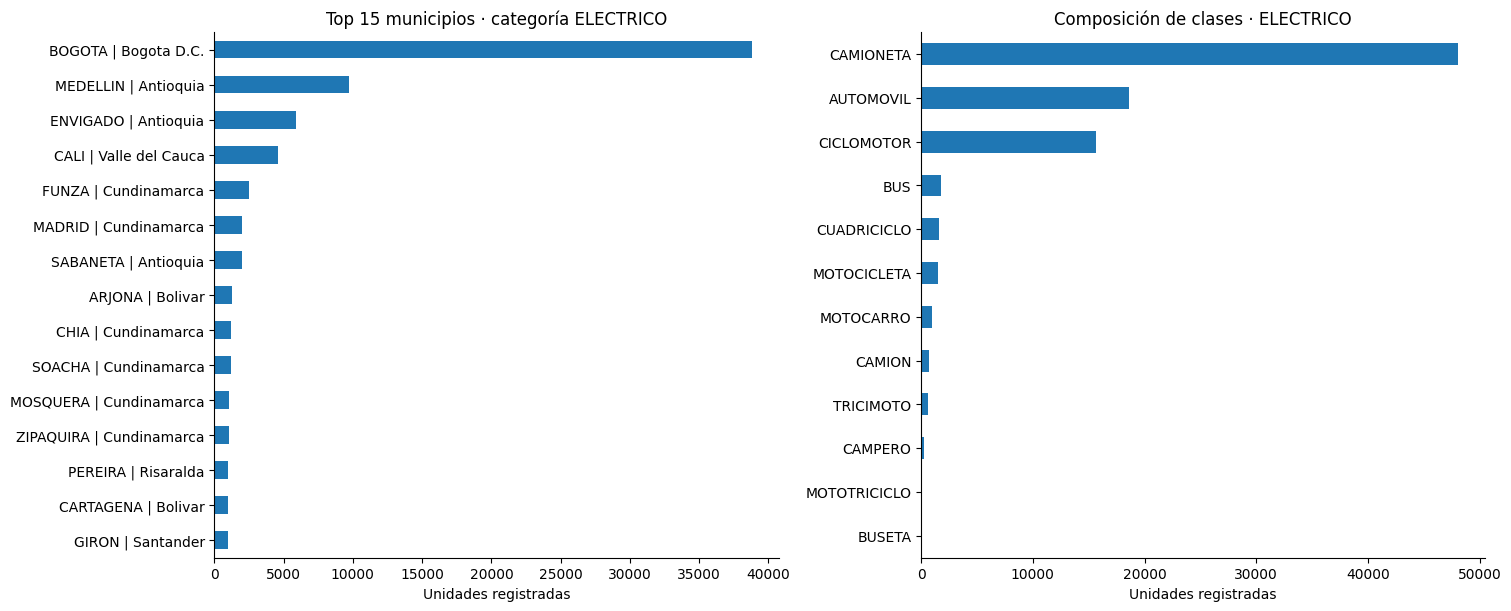

In [7]:
bev=df.loc[df['COMBUSTIBLE'].eq('ELECTRICO')].copy()
bev_city=bev.groupby('MUNICIPIO_DPTO',observed=True)['CANTIDAD_NUM'].sum().sort_values(ascending=False)
bev_classes=bev.groupby('CLASE',observed=True)['CANTIDAD_NUM'].sum().sort_values(ascending=False)
print('Vehículos eléctricos:',int(bev.CANTIDAD_NUM.sum()),'| municipios:',bev_city.size)
display(bev_city.head(20).to_frame('electricos'))
display(bev_classes.to_frame('electricos'))
bev_city.rename('electricos').to_csv(OUT/'tables'/'electricos_por_municipio_bruto.csv',encoding='utf-8-sig')
fig,axs=plt.subplots(1,2,figsize=(15,6),constrained_layout=True)
bev_city.head(15).sort_values().plot.barh(ax=axs[0]);axs[0].set(title='Top 15 municipios · categoría ELECTRICO',xlabel='Unidades registradas',ylabel='')
bev_classes.head(12).sort_values().plot.barh(ax=axs[1]);axs[1].set(title='Composición de clases · ELECTRICO',xlabel='Unidades registradas',ylabel='')
fig.savefig(OUT/'figures'/'03_electricos_municipios_clases.png',bbox_inches='tight');plt.show()

## 7 · Sensibilidad de clasificación y del año 2026
**Pregunta:** ¿Cuánto cambia la shortlist municipal si contamos todos los eléctricos o sólo clases que podrían ser más pertinentes para autos particulares?  
**Escenarios exploratorios:** A = todos los `ELECTRICO`; B = `AUTOMOVIL`, `CAMIONETA`, `CAMPERO` eléctricos (sólo proxy de pasajeros, sujeto a validación); C = B excluyendo matriculaciones del año 2026 (no equivale a parque activo).  
**Métrica:** comparación de Top 10, concordancia de rangos Spearman/Kendall para el universo de municipios con al menos 1 eléctrico en A. La decisión de restringir clases es un escenario, no una verdad normativa sobre el mercado de carga.

In [8]:
passenger=['AUTOMOVIL','CAMIONETA','CAMPERO']
scenario={
 'A_todos_electricos':bev,
 'B_pasajeros_electricos':bev.loc[bev['CLASE'].isin(passenger)],
 'C_pasajeros_hasta_2025':bev.loc[bev['CLASE'].isin(passenger)&bev['REGISTRO_ANO'].le(2025)],
}
rankings={k:v.groupby('MUNICIPIO_DPTO')['CANTIDAD_NUM'].sum().reindex(bev_city.index,fill_value=0) for k,v in scenario.items()}
base_top=set(rankings['A_todos_electricos'].nlargest(10).index)
res=[]
for name,series in rankings.items():
    top=list(series.nlargest(10).index); overlap=len(set(top)&base_top)
    rho,p=spearmanr(rankings['A_todos_electricos'].rank(method='average'),series.rank(method='average'))
    tau,_=kendalltau(rankings['A_todos_electricos'].rank(method='average'),series.rank(method='average'))
    res.append([name,int(series.sum()),int((series>0).sum()),overlap,round(float(rho),4),round(float(tau),4),'; '.join(top)])
sensitivity=pd.DataFrame(res,columns=['escenario','vehiculos','municipios_con_registros','coincidencia_top10_con_A','spearman_rho_A','kendall_tau_A','top10_ordenado'])
display(sensitivity)
sensitivity.to_csv(OUT/'tables'/'sensibilidad_escenarios_runt.csv',index=False,encoding='utf-8-sig')
print('No interpretar valores p de concordancia como incertidumbre de muestreo de un censo administrativo. Se reportan magnitudes, no inferencia causal.')

,escenario,vehiculos,municipios_con_registros,coincidencia_top10_con_A,spearman_rho_A,kendall_tau_A,top10_ordenado
0,A_todos_electricos,89900,237,10,1.0000,1.0000,BOGOTA | Bogota D.C.; MEDELLIN | Antioquia; ENVIGADO | Antioquia; CALI | Valle del Cau...
1,B_pasajeros_electricos,66981,154,7,0.7572,0.6178,BOGOTA | Bogota D.C.; MEDELLIN | Antioquia; ENVIGADO | Antioquia; CALI | Valle del Cau...
2,C_pasajeros_hasta_2025,36308,142,7,0.7456,0.6122,BOGOTA | Bogota D.C.; MEDELLIN | Antioquia; ENVIGADO | Antioquia; CALI | Valle del Cau...


No interpretar valores p de concordancia como incertidumbre de muestreo de un censo administrativo. Se reportan magnitudes, no inferencia causal.


## 8 · Concentración territorial, diferencias de años modelo y restricciones
**Pregunta:** ¿Están los registros concentrados en pocos municipios, y es plausible hablar de una demanda localizada?  
**Método:** participaciones Top 1/5/10 y HHI descriptivo. Se revisa brecha entre año modelo y año registro; valores futuros pueden ser legítimos y deben contrastarse con documentación.

,valor
top1_pct,43.15000
top5_pct,68.36000
top10_pct,76.86000
HHI,0.20846


Brecha modelo - registro (años):


,size,sum
brecha_modelo_registro,,
-24,1,1
-17,1,1
-16,1,1
-15,3,3
-11,1,1
-10,2,2
-9,1,1
-8,5,6
-7,9,9


Año registro 2026, eléctricos: 31641


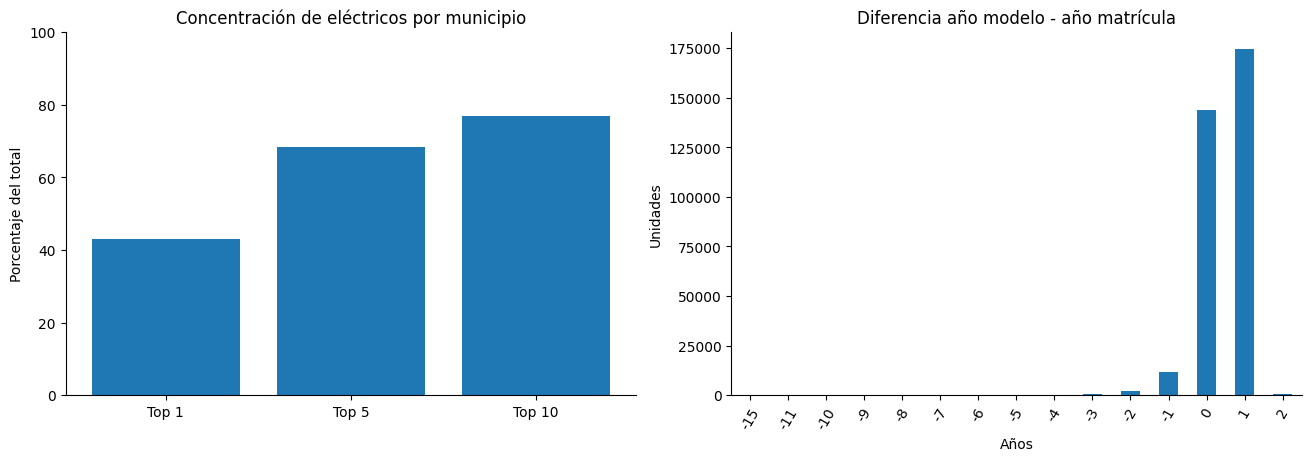

In [9]:
city_shares=bev_city/bev_city.sum()
concentration={'top1_pct':round(city_shares.head(1).sum()*100,2),'top5_pct':round(city_shares.head(5).sum()*100,2),'top10_pct':round(city_shares.head(10).sum()*100,2),'HHI':round(float((city_shares**2).sum()),5)}
display(pd.Series(concentration,name='valor').to_frame())
df['brecha_modelo_registro']=df['MODELO_ANO']-df['REGISTRO_ANO']
gap=df.groupby('brecha_modelo_registro')['CANTIDAD_NUM'].agg(['size','sum']).sort_index()
print('Brecha modelo - registro (años):');display(gap.tail(20))
print('Año registro 2026, eléctricos:',int(bev.loc[bev['REGISTRO_ANO']==2026,'CANTIDAD_NUM'].sum()))
fig,axs=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
axs[0].bar(['Top 1','Top 5','Top 10'],[concentration['top1_pct'],concentration['top5_pct'],concentration['top10_pct']]);axs[0].set(title='Concentración de eléctricos por municipio',ylabel='Porcentaje del total',ylim=(0,100))
gap.loc[(gap.index>=-15)&(gap.index<=2),'sum'].plot.bar(ax=axs[1]);axs[1].set(title='Diferencia año modelo - año matrícula',xlabel='Años',ylabel='Unidades');axs[1].tick_params(axis='x',rotation=60)
fig.savefig(OUT/'figures'/'04_concentracion_y_brecha_modelo.png',bbox_inches='tight');plt.show()

## 9 · Matriz de decisiones estadísticas y metodológicas
El objetivo no es acumular pruebas: el archivo es administrativo, agregado y no tiene etiqueta de resultado comercial. Pruebas clásicas de normalidad o modelos de predicción de utilización no responden una pregunta válida con estas columnas. Se registran descartes y sus razones, además de las técnicas efectivamente aplicadas.

In [10]:
decisions=pd.DataFrame([
 ['¿Cuántos vehículos representa cada fila?','Suma ponderada de CANTIDAD','La observación es agrupada, no individual','CANTIDAD describe unidades, con formato validado','Conversion y positivos verificados','Contar filas','Contar filas infravalora los totales',str(checks['cantidad_vehiculos'])+' vehículos','Es un total de categorías administrativas','No es parque activo confirmado','Usar suma ponderada'],
 ['¿El combustible define carga enchufable?','Desagregación de COMBUSTIBLE y escenario ELECTRICO','No confundir HEV y PHEV','Categorías del archivo según nomenclatura original','Cuatro categorías observadas','Agrupar toda categoría híbrida','No hay etiqueta de enchufabilidad','ELECTRICO='+str(int(fuel.get('ELECTRICO',0))),'El universo eléctrico puro puede aislarse','No mide uso real de cargadores','Usar ELECTRICO para primer proxy'],
 ['¿Son comparables años 2025 y 2026?','Serie anual descriptiva con advertencia','2026 no es año cerrado','El año anual es válido y años extremos se interpretan','El rango anual se verificó','Tasa 2026/2025','Un año parcial sesga la comparación','2026='+str(checks['anio_2026_vehiculos']),'No permite inferir crecimiento interanual comparable','Falta fecha mensual y fecha de corte','No inferir crecimiento a 12 meses'],
 ['¿Hay errores por valores grandes de CANTIDAD?','Regla IQR sobre tamaños de celda; revisión, sin filtrado','Agrupaciones grandes no son mediciones individuales anómalas','Unidades positivas; heterogeneidad legítima','No se encontraron cantidades negativas','Isolation Forest/LOF','No aporta sin atributos de celdas comparables y escalamiento justificado',str(int(stats['filas_por_encima_Tukey']))+' filas sobre cerca Tukey','Alertas descriptivas, no falsedad','No se conoce cardinalidad real de subpoblaciones','Conservar extremos'],
 ['¿Cómo varía la preselección por clases?','Escenarios A/B/C; concordancia y Top10','Los criterios de elegibilidad son decisiones sustantivas','Comparación misma clave municipal','Las categorías de CLASE se inspeccionaron','Bootstrap de filas','Las filas agregadas no son muestra aleatoria independiente',f"A vs B: {int(sensitivity.iloc[1]['coincidencia_top10_con_A'])}/10 en Top10",'Evalúa estabilidad de shortlist bajo filtros','No es ranking final; municipio de matrícula no equivale a mercado','Validar alcance de clases con expertos'],
 ['¿Concentran pocas ciudades los eléctricos?','Top-k y HHI','Magnitud descriptiva sin suponer distribución paramétrica','Municipio+departamento distingue homónimos','Se verificó clave compuesta','Chi-cuadrado para causa de concentración','Sin diseño de muestreo causal ni hipótesis de comparación pertinente',str(concentration),'Muestra concentración de matrículas','No explica consumo o movilidad','Triangular contra oferta, población y movilidad'],
 ['¿Necesita CANTIDAD normalidad?','Descartadas Shapiro / Anderson y Q-Q inferencial','No se requiere normalidad para sumas agregadas multicriterio','Datos son celdas y enteros sesgados','Unidades y distribución comprobadas','Transformación automática normalizante','Alteraría la interpretación sin responder pregunta','No aplicado','No afecta el cálculo descriptivo','Si se usa método posterior, reevaluar supuestos','No ejecutar normalidad mecánica'],
 ['¿Conviene PCA / clustering?','Diferidos hasta construir indicadores municipales','Una única fuente y variables categóricas originales no constituyen matriz municipal multicriterio','Se requieren indicadores comparables y cobertura','Aún falta DANE, infraestructura, OSM','PCA sobre columnas brutas','Mezclaría atributos de celdas con características de ciudades','No aplicado','Sería prematuro','Se deben harmonizar DIVIPOLA y fuentes','Reevaluar en integración posterior'],
],columns=['pregunta_analitica','tecnica_seleccionada','justificacion','supuestos','validacion','alternativas','motivo_de_seleccion','resultado','interpretacion','limitaciones','decision'])
display(decisions)
decisions.to_csv(OUT/'tables'/'matriz_decisiones_estadisticas_runt.csv',index=False,encoding='utf-8-sig')

,pregunta_analitica,tecnica_seleccionada,justificacion,supuestos,validacion,alternativas,motivo_de_seleccion,resultado,interpretacion,limitaciones,decision
0,¿Cuántos vehículos representa cada fila?,Suma ponderada de CANTIDAD,"La observación es agrupada, no individual","CANTIDAD describe unidades, con formato validado",Conversion y positivos verificados,Contar filas,Contar filas infravalora los totales,332901 vehículos,Es un total de categorías administrativas,No es parque activo confirmado,Usar suma ponderada
1,¿El combustible define carga enchufable?,Desagregación de COMBUSTIBLE y escenario ELECTRICO,No confundir HEV y PHEV,Categorías del archivo según nomenclatura original,Cuatro categorías observadas,Agrupar toda categoría híbrida,No hay etiqueta de enchufabilidad,ELECTRICO=89900,El universo eléctrico puro puede aislarse,No mide uso real de cargadores,Usar ELECTRICO para primer proxy
2,¿Son comparables años 2025 y 2026?,Serie anual descriptiva con advertencia,2026 no es año cerrado,El año anual es válido y años extremos se interpretan,El rango anual se verificó,Tasa 2026/2025,Un año parcial sesga la comparación,2026=87961,No permite inferir crecimiento interanual comparable,Falta fecha mensual y fecha de corte,No inferir crecimiento a 12 meses
3,¿Hay errores por valores grandes de CANTIDAD?,"Regla IQR sobre tamaños de celda; revisión, sin filtrado",Agrupaciones grandes no son mediciones individuales anómalas,Unidades positivas; heterogeneidad legítima,No se encontraron cantidades negativas,Isolation Forest/LOF,No aporta sin atributos de celdas comparables y escalamiento justificado,1592 filas sobre cerca Tukey,"Alertas descriptivas, no falsedad",No se conoce cardinalidad real de subpoblaciones,Conservar extremos
4,¿Cómo varía la preselección por clases?,Escenarios A/B/C; concordancia y Top10,Los criterios de elegibilidad son decisiones sustantivas,Comparación misma clave municipal,Las categorías de CLASE se inspeccionaron,Bootstrap de filas,Las filas agregadas no son muestra aleatoria independiente,A vs B: 7/10 en Top10,Evalúa estabilidad de shortlist bajo filtros,No es ranking final; municipio de matrícula no equivale a mercado,Validar alcance de clases con expertos
5,¿Concentran pocas ciudades los eléctricos?,Top-k y HHI,Magnitud descriptiva sin suponer distribución paramétrica,Municipio+departamento distingue homónimos,Se verificó clave compuesta,Chi-cuadrado para causa de concentración,Sin diseño de muestreo causal ni hipótesis de comparación pertinente,"{'top1_pct': np.float64(43.15), 'top5_pct': np.float64(68.36), 'top10_pct': np.float64...",Muestra concentración de matrículas,No explica consumo o movilidad,"Triangular contra oferta, población y movilidad"
6,¿Necesita CANTIDAD normalidad?,Descartadas Shapiro / Anderson y Q-Q inferencial,No se requiere normalidad para sumas agregadas multicriterio,Datos son celdas y enteros sesgados,Unidades y distribución comprobadas,Transformación automática normalizante,Alteraría la interpretación sin responder pregunta,No aplicado,No afecta el cálculo descriptivo,"Si se usa método posterior, reevaluar supuestos",No ejecutar normalidad mecánica
7,¿Conviene PCA / clustering?,Diferidos hasta construir indicadores municipales,Una única fuente y variables categóricas originales no constituyen matriz municipal mu...,Se requieren indicadores comparables y cobertura,"Aún falta DANE, infraestructura, OSM",PCA sobre columnas brutas,Mezclaría atributos de celdas con características de ciudades,No aplicado,Sería prematuro,Se deben harmonizar DIVIPOLA y fuentes,Reevaluar en integración posterior


## 10 · Matriz de hallazgos y síntesis final
No se introducen afirmaciones causales sobre instalaciones de electrolineras. Cada resultado se clasifica como observado/derivado, decisión metodológica o pendiente de validación. Una robustez baja/indeterminada se declara aunque el gráfico parezca concluyente.

In [11]:
findings=pd.DataFrame([
 ['H01','¿Cuántos registros hay?','Filas='+str(checks['filas'])+'; vehículos='+str(checks['cantidad_vehiculos']),'Agregación ponderada','Confirmado','Alta como suma del archivo','Define unidad válida para EDA','No confirma universo activo','Usar CANTIDAD_NUM','Alta'],
 ['H02','¿Qué proporción es categoría ELECTRICO?',f"{int(fuel.get('ELECTRICO',0))} / {int(fuel.sum())} = {fuel.get('ELECTRICO',0)/fuel.sum()*100:.2f}%",'Agregación por combustible','Confirmado','Alta dentro de la codificación original','Evita sobreestimar demanda enchufable','No separa tipos de híbridos','Filtrar eléctricos; validar diccionario','Alta'],
 ['H03','¿Se puede medir aumento mensual?','AÑO_REGISTRO sin mes','Auditoría de esquema','Confirmado','Alta','Impide KPI móvil de 12 meses','Se desconoce disponibilidad en otras fuentes','Complementar con fuente mensual','Alta'],
 ['H04','¿Hay calidad suficiente para usar como proxy?',f"NA={checks['faltantes_totales']}; duplicados exactos={checks['filas_exactamente_duplicadas']}",'Auditoría de completitud y claves','Confirmado','Alta en campos del CSV','Buen punto de partida para calidad de Guía 4','No demuestra cobertura exhaustiva','No imputar sin necesidad','Media'],
 ['H05','¿Qué tan concentrados están los eléctricos?',f"Top10={concentration['top10_pct']}%; HHI={concentration['HHI']}",'Agregación territorial','Confirmado','Alta como distribución de matrículas','Precaución por concentración administrativa','Ciudad de matrícula ≠ ciudad de demanda','Triangular con oferta/población','Alta'],
 ['H06','¿Qué efecto tiene el filtro de clases?',f"Top10 A/B={int(sensitivity.iloc[1]['coincidencia_top10_con_A'])}/10",'Sensibilidad de escenarios','Confirmado','Moderada','Shortlist puede depender de elegibilidad','Clases no se traducen directamente a demanda pública','Validar con expertos','Alta'],
 ['H07','¿Hay coherencia temporal entre año modelo y matrícula?',f"{checks['modelo_posterior_registro_filas']} filas con modelo posterior; de ellas >1 año: {checks['modelo_posterior_en_mas_de_un_ano_filas']}",'Regla de relación entre campos','Confirmado para conteo, causa desconocida','Indeterminada','Requiere regla de negocio','Modelo siguiente puede ser normal','No eliminar; confirmar semántica','Media'],
],columns=['id','pregunta','evidencia','tecnica','estado_evidencia','robustez','relevancia_negocio','limitacion','accion','prioridad'])
display(findings)
findings.to_csv(OUT/'tables'/'matriz_hallazgos_runt.csv',index=False,encoding='utf-8-sig')
print('Archivos de resultados escritos en',OUT.resolve())

,id,pregunta,evidencia,tecnica,estado_evidencia,robustez,relevancia_negocio,limitacion,accion,prioridad
0,H01,¿Cuántos registros hay?,Filas=10748; vehículos=332901,Agregación ponderada,Confirmado,Alta como suma del archivo,Define unidad válida para EDA,No confirma universo activo,Usar CANTIDAD_NUM,Alta
1,H02,¿Qué proporción es categoría ELECTRICO?,89900 / 332901 = 27.01%,Agregación por combustible,Confirmado,Alta dentro de la codificación original,Evita sobreestimar demanda enchufable,No separa tipos de híbridos,Filtrar eléctricos; validar diccionario,Alta
2,H03,¿Se puede medir aumento mensual?,AÑO_REGISTRO sin mes,Auditoría de esquema,Confirmado,Alta,Impide KPI móvil de 12 meses,Se desconoce disponibilidad en otras fuentes,Complementar con fuente mensual,Alta
3,H04,¿Hay calidad suficiente para usar como proxy?,NA=1; duplicados exactos=0,Auditoría de completitud y claves,Confirmado,Alta en campos del CSV,Buen punto de partida para calidad de Guía 4,No demuestra cobertura exhaustiva,No imputar sin necesidad,Media
4,H05,¿Qué tan concentrados están los eléctricos?,Top10=76.86%; HHI=0.20846,Agregación territorial,Confirmado,Alta como distribución de matrículas,Precaución por concentración administrativa,Ciudad de matrícula ≠ ciudad de demanda,Triangular con oferta/población,Alta
5,H06,¿Qué efecto tiene el filtro de clases?,Top10 A/B=7/10,Sensibilidad de escenarios,Confirmado,Moderada,Shortlist puede depender de elegibilidad,Clases no se traducen directamente a demanda pública,Validar con expertos,Alta
6,H07,¿Hay coherencia temporal entre año modelo y matrícula?,3694 filas con modelo posterior; de ellas >1 año: 60,Regla de relación entre campos,"Confirmado para conteo, causa desconocida",Indeterminada,Requiere regla de negocio,Modelo siguiente puede ser normal,No eliminar; confirmar semántica,Media


Archivos de resultados escritos en /mnt/data/DataWizards_RUNT_Guia4/reports


## 11 · Conclusiones ejecutivas y próximos pasos
1. **Apto con reservas** como fuente parcial de demanda potencial: permite cuantificar vehículos en la categoría `ELECTRICO` por municipio/año de matrícula, con clases y año modelo.
2. **No es suficiente** por sí solo para priorizar inversión ni para estimar utilización, localización efectiva o rentabilidad de estaciones.
3. **No incluye mes**: no soporta el KPI de crecimiento móvil de 12 meses planteado en Guía 2; debe buscarse fuente complementaria o formalizarse un indicador alterno.
4. **2026 es parcial** y los totales del año pueden contener registros de diferente corte; debe documentarse la fecha de actualización y evitar inferir tasas anuales comparables.
5. **No imputar automáticamente** el campo `CARROCERIA`; no eliminar tamaños extremos de celdas ni filas con año modelo siguiente.
6. **Separar tecnologías**, pues los híbridos no son necesariamente enchufables.
7. **Cruzar con DIVIPOLA** para homogeneizar municipios, y posteriormente con población, red vial y oferta de carga.
8. **Validar categoría de vehículos relevante** con el alcance de la decisión (automóviles particulares vs motocicletas, buses, flota comercial).
9. **No ejecutar pruebas de normalidad o ML por cumplir un listado**: cada técnica debe corresponder a una hipótesis defendible con la unidad de observación.

### Ruta analítica sugerida
- **Fase de datos:** confirmar metadatos del RUNT; incorporar tabla DIVIPOLA y fuente mensual; revisar categoría tecnológica.
- **Fase de preparación:** definir denominadores por población y métricas de antigüedad; estandarizar cortes y cobertura territorial.
- **Fase de integración:** combinar demanda eléctrica con disponibilidad de carga y accesibilidad; auditar faltantes, relaciones y redundancias en unidad *ciudad*.
- **Fase de decisión:** índice multicriterio explicable y sensibilidad de pesos, contraste con expertos y baseline ingenuo, *sin* etiquetar los resultados como utilidad financiera probada.

### Límites de esta entrega
Análisis de una fuente administrativa agregada; sin estimación del proceso de captura del RUNT, ni evaluación de sesgo de cobertura por subregistro, ni test externo de confiabilidad, ni validación contra operadores. Resultados no extrapolables a tráfico/consumo de cargadores.